### 1. Persiapan Environment

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from skimage.feature import graycomatrix, graycoprops
from skimage.morphology import remove_small_objects
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    classification_report, confusion_matrix
)

# 2. Load Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
DATASET_TRAIN_PATH = "/content/drive/MyDrive/PCR_Kelompok_6/Dataset/hasnain/train"
DATASET_TEST_PATH = "/content/drive/MyDrive/PCR_Kelompok_6/Dataset/hasnain/test"

CATEGORIES = ["benign", "malignant"]
IMG_SIZE = 128

In [ ]:
print(os.listdir(DATASET_TRAIN_PATH))
print(os.listdir(DATASET_TEST_PATH))

['malignant', 'benign']
['benign', 'malignant']


# 3. Pra-Pemrosesan Citra

In [ ]:
def preprocess_image(path):
    img = cv2.imread(path)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return img

# 4. Segmentasi Lesi (K-Means Clustering)

In [ ]:
def segment_lesion(image, k=2):
    img = image.reshape((-1, 3))
    img = np.float32(img)

    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(img)

    segmented = labels.reshape((IMG_SIZE, IMG_SIZE))

    # Ambil cluster paling gelap (diasumsikan lesi)
    cluster_means = [
        np.mean(image[segmented == i])
        for i in range(k)
    ]
    lesion_cluster = np.argmin(cluster_means)

    mask = (segmented == lesion_cluster)
    return mask

# 5. Pasca-Pemrosesan Segmentasi (Morfologi)

In [ ]:
def postprocess_mask(mask):
    mask = remove_small_objects(mask, min_size=60)
    return mask.astype(np.uint8)

# 6. Ekstraksi Fitur (Fitur Tekstur (GLCM))

In [ ]:
def extract_features(image, mask):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    gray = gray * mask

    glcm = graycomatrix(
        gray,
        distances=[1],
        angles=[0],
        levels=256,
        symmetric=True,
        normed=True
    )

    contrast = graycoprops(glcm, 'contrast')[0,0]
    correlation = graycoprops(glcm, 'correlation')[0,0]
    energy = graycoprops(glcm, 'energy')[0,0]
    homogeneity = graycoprops(glcm, 'homogeneity')[0,0]

    area = np.sum(mask)
    perimeter = cv2.countNonZero(
        cv2.Canny((mask*255).astype(np.uint8), 100, 200)
    )

    return [contrast, correlation, energy, homogeneity, area, perimeter]

# 7. Load Data + Feature Extraction

In [ ]:
X_train = []
y_train = []

for category in CATEGORIES:
    folder = os.path.join(DATASET_TRAIN_PATH, category)
    label = CATEGORIES.index(category)

    for file in os.listdir(folder):
        path = os.path.join(folder, file)

        img = preprocess_image(path)
        mask = segment_lesion(img)
        mask = postprocess_mask(mask)

        features = extract_features(img, mask)
        X_train.append(features)
        y_train.append(label)

X_train = np.array(X_train)
y_train = np.array(y_train)

print("Data shape:", X_train.shape)


Data shape: (9605, 6)


In [ ]:
print(features)

[np.float64(51.397945374015755), np.float64(0.8156908252128497), np.float64(0.9543576306208896), np.float64(0.9604847810977628), np.uint64(711), 170]


In [ ]:
X_test = []
y_test = []

for category in CATEGORIES:
    folder = os.path.join(DATASET_TEST_PATH, category)
    label = CATEGORIES.index(category)

    for file in os.listdir(folder):
        path = os.path.join(folder, file)

        img = preprocess_image(path)
        mask = segment_lesion(img)
        mask = postprocess_mask(mask)

        features = extract_features(img, mask)
        X_test.append(features)
        y_test.append(label)

X_test = np.array(X_test)
y_test = np.array(y_test)

print("Data shape:", X_test.shape)


Data shape: (1000, 6)


# 8. Visualisasi Segmentasi

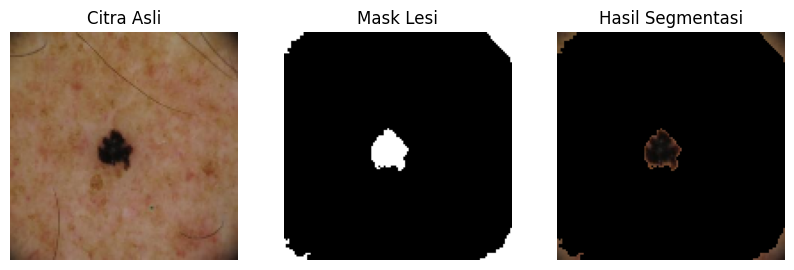

In [ ]:
sample_img = preprocess_image(path)
sample_mask = postprocess_mask(segment_lesion(sample_img))

plt.figure(figsize=(10,4))

plt.subplot(1,3,1)
plt.imshow(sample_img)
plt.title("Citra Asli")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(sample_mask, cmap="gray")
plt.title("Mask Lesi")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(sample_img * sample_mask[...,None])
plt.title("Hasil Segmentasi")
plt.axis("off")

plt.show()


In [ ]:
print(os.path.basename(path))

melanoma_10544.jpg


# 9. Normalisasi Fitur


In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# 10. Klasifikasi SVM

In [ ]:
svm_linear = SVC(kernel='linear')
svm_poly = SVC(kernel='poly')
svm_rbf = SVC(kernel='rbf')

svm_linear.fit(X_train, y_train)
svm_poly.fit(X_train, y_train)
svm_rbf.fit(X_train, y_train)

y_pred_linear = svm_linear.predict(X_test)
y_pred_poly = svm_poly.predict(X_test)
y_pred_rbf = svm_rbf.predict(X_test)


# 11. Evaluasi Kinerja

In [ ]:
accuracy = accuracy_score(y_test, y_pred_linear)
print("Accuracy SVM poly:", accuracy)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_linear, target_names=CATEGORIES))


Accuracy SVM poly: 0.795

Classification Report:

              precision    recall  f1-score   support

      benign       0.78      0.83      0.80       500
   malignant       0.81      0.76      0.79       500

    accuracy                           0.80      1000
   macro avg       0.80      0.79      0.79      1000
weighted avg       0.80      0.80      0.79      1000



In [ ]:
accuracy = accuracy_score(y_test, y_pred_poly)
print("Accuracy SVM poly:", accuracy)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_poly, target_names=CATEGORIES))


Accuracy SVM poly: 0.769

Classification Report:

              precision    recall  f1-score   support

      benign       0.71      0.92      0.80       500
   malignant       0.89      0.62      0.73       500

    accuracy                           0.77      1000
   macro avg       0.80      0.77      0.76      1000
weighted avg       0.80      0.77      0.76      1000



In [ ]:
accuracy = accuracy_score(y_test, y_pred_rbf)
print("Accuracy SVM rbf:", accuracy)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_rbf, target_names=CATEGORIES))


Accuracy SVM rbf: 0.812

Classification Report:

              precision    recall  f1-score   support

      benign       0.86      0.75      0.80       500
   malignant       0.78      0.88      0.82       500

    accuracy                           0.81      1000
   macro avg       0.82      0.81      0.81      1000
weighted avg       0.82      0.81      0.81      1000



In [ ]:
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': [1, 0.1, 0.01, 0.001],
}

model_tunning = GridSearchCV(estimator=svm_rbf, param_grid=param_grid, cv=10, scoring='accuracy', verbose=2)
model_tunning.fit(X_train, y_train)

print("Parameter rbf terbaik:", model_tunning.best_params_)

Fitting 10 folds for each of 16 candidates, totalling 160 fits
[CV] END .....................................C=0.1, gamma=1; total time=   4.6s
[CV] END .....................................C=0.1, gamma=1; total time=   6.3s
[CV] END .....................................C=0.1, gamma=1; total time=   6.0s
[CV] END .....................................C=0.1, gamma=1; total time=   7.4s
[CV] END .....................................C=0.1, gamma=1; total time=   4.5s
[CV] END .....................................C=0.1, gamma=1; total time=   7.0s
[CV] END .....................................C=0.1, gamma=1; total time=   5.9s
[CV] END .....................................C=0.1, gamma=1; total time=   3.4s
[CV] END .....................................C=0.1, gamma=1; total time=   2.5s
[CV] END .....................................C=0.1, gamma=1; total time=   3.7s
[CV] END ...................................C=0.1, gamma=0.1; total time=   2.5s
[CV] END ...................................C=

In [ ]:
best_model = model_tunning.best_estimator_
y_pred_best_model = best_model.predict(X_test)
accuracy_best_model = accuracy_score(y_test, y_pred_best_model)

print("Akurasi SVM RBF setelah tuning:", accuracy_best_model)
print("\nLaporan Klasifikasi kernel rbf:\n", classification_report(y_test, y_pred_best_model))

Akurasi SVM RBF setelah tuning: 0.83

Laporan Klasifikasi kernel rbf:
               precision    recall  f1-score   support

           0       0.82      0.84      0.83       500
           1       0.84      0.82      0.83       500

    accuracy                           0.83      1000
   macro avg       0.83      0.83      0.83      1000
weighted avg       0.83      0.83      0.83      1000



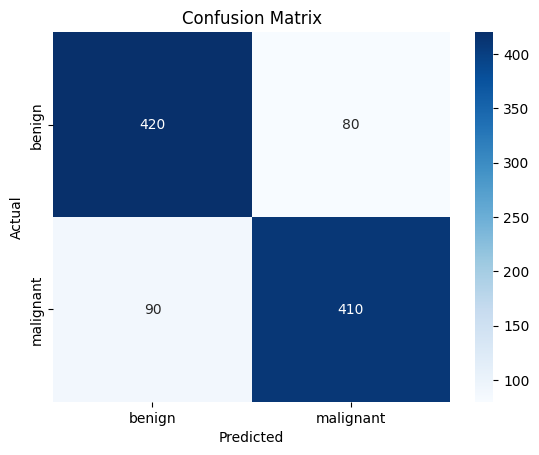

In [ ]:
cm = confusion_matrix(y_test, y_pred_best_model)

sns.heatmap(
    cm, annot=True, fmt="d",
    xticklabels=CATEGORIES,
    yticklabels=CATEGORIES,
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

